# Reto 1 · Exploración y calidad de datos (EDA)

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Objetivo: entender la base de clientes antes de segmentarla. Este notebook cubre:

1. Estructura y granularidad del dataset
2. Columnas de metadatos / identificadores y su exclusión justificada
3. Estadísticas descriptivas de las variables principales
4. Valores nulos e inconsistencias, con propuesta de tratamiento
5. Distribuciones de variables clave
6. Resumen de hallazgos y conclusiones

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

## 1. Carga y estructura

In [2]:
raw = mf.load_raw(CSV)
print(f"Filas: {raw.shape[0]:,} · Columnas: {raw.shape[1]}")
raw.head(3).T

Filas: 302,850 · Columnas: 39


,0,1,2
Unnamed: 0,0,1,2
client_id,000144e39c02702f821f69beeb7036f40cf8505051050f...,000144e39c02702f821f69beeb7036f40cf8505051050f...,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fab...
vehicle_id,db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba6...,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...,716e4f639ce69defa3b9ce202848cdca612814e7d0dc47...
age_range,35-44,35-44,25-34
gender_derived,female,female,male
model_series,177,206,213
vehicle_type,A 180 d,C 200 d,AMG E 63 S 4MATIC+
model_class,A-Class,C-Class,E-Class
product_group,P,P,P
engine_concept,NaN,NaN,COMBUSTION


In [3]:
pd.DataFrame({"dtype": raw.dtypes.astype(str),
              "n_unique": raw.nunique(),
              "% nulos": (raw.isna().mean() * 100).round(1)})

,dtype,n_unique,% nulos
Unnamed: 0,int64,302850,0.0
client_id,str,173456,0.0
vehicle_id,str,244519,0.0
age_range,str,6,0.0
gender_derived,str,2,11.2
model_series,int64,88,0.0
vehicle_type,str,1436,0.3
model_class,str,42,1.1
product_group,str,4,0.0
engine_concept,str,4,44.4


### Granularidad: ¿qué es una fila?

El diccionario mezcla atributos de **cliente** y de **vehículo**. Comprobamos qué representa cada fila.

In [4]:
n_clients = raw.client_id.nunique()
n_vehicles = raw.vehicle_id.nunique()
per_client = raw.groupby("client_id").size()
print(f"Clientes únicos:  {n_clients:,}")
print(f"Vehículos únicos: {n_vehicles:,}")
print(f"Pares (cliente, vehículo) duplicados: {raw.duplicated(['client_id','vehicle_id']).sum():,}")
print(f"Vehículos compartidos por >1 cliente: {(raw.groupby('vehicle_id').client_id.nunique() > 1).sum():,}")
per_client.describe(percentiles=[.5, .75, .9, .99]).round(2)

Clientes únicos:  173,456
Vehículos únicos: 244,519
Pares (cliente, vehículo) duplicados: 0


Vehículos compartidos por >1 cliente: 46,648


count    173456.00
mean          1.75
std           5.51
min           1.00
50%           1.00
75%           2.00
90%           2.00
99%          10.00
max         561.00
dtype: float64

In [5]:
# ¿Qué columnas son constantes dentro de cada cliente? -> atributos de cliente
g = raw.groupby("client_id")
const = {c: int((g[c].nunique(dropna=False) > 1).sum()) for c in raw.columns if c not in ("client_id", "Unnamed: 0")}
pd.Series(const, name="clientes con >1 valor").sort_values().to_frame()

,clientes con >1 valor
age_range,0
gender_derived,0
currently_connected_vehicles,0
country_code,0
months_as_mb_customer,0
consent_epost_communication_channel,0
consent_phone_communication_channel,0
finance_leasing_status,0
zipcode,0
population,0


**Conclusión:** cada fila es una **relación cliente-vehículo** (302.850 filas, 173.456 clientes, 1,75 vehículos por cliente de media,
con una cola de hasta 561 vehículos en cuentas de flota).

- Edad, género, antigüedad como cliente, financiación, consentimientos y datos de la zona son **constantes por cliente**.
- Modelo, motorización, fecha de matriculación, visitas a taller y telemetría son **atributos del vehículo**.
- `role_type` varía en 545 clientes (son conductores B2B de un vehículo y particulares en otro).

Como el reto pide **segmentar clientes**, el modelo trabajará con una tabla de **1 fila = 1 cliente**
(ver notebook 02). Hacer clustering a nivel fila daría más peso a quien tiene más coches y partiría a un mismo cliente en varios segmentos.

## 2. Columnas de metadatos e identificadores

| Columna | Motivo de exclusión del modelo |
|---|---|
| `Unnamed: 0` | Índice exportado del DataFrame original: secuencial 0…n, sin significado. |
| `client_id` | Hash identificador. Se usa como **clave de agregación**, nunca como feature. |
| `vehicle_id` | Hash identificador del vehículo. Solo sirve para contar vehículos por cliente. |
| `zipcode` | Clave geográfica de alta cardinalidad; su información útil ya viene en las variables de poder adquisitivo. |
| `model_series`, `vehicle_type` | Códigos de alta cardinalidad (cientos de valores); se resumen en `model_class` → gama comercial. |
| `trip_distance_mode`, `speed_mode` | Strings con varias modas concatenadas (`"2.5,7.5,15,…"`), no numéricas; redundantes con media/mediana. |
| `*_all_counter` | Contadores técnicos de cuántas mediciones se usaron; no describen al cliente. |

In [6]:
for c in ["Unnamed: 0", "client_id", "vehicle_id", "zipcode", "model_series", "vehicle_type"]:
    print(f"{c:<22} únicos: {raw[c].nunique():>8,}")
print("\nUnnamed: 0 es exactamente 0..n-1:", (raw["Unnamed: 0"].values == np.arange(len(raw))).all())
print("\nEjemplos de trip_distance_mode con varias modas:")
print(raw.trip_distance_mode[raw.trip_distance_mode.str.contains(",", na=False)].value_counts().head(4))

Unnamed: 0             únicos:  302,850
client_id              únicos:  173,456
vehicle_id             únicos:  244,519
zipcode                únicos:    4,610
model_series           únicos:       88
vehicle_type           únicos:    1,436

Unnamed: 0 es exactamente 0..n-1: True

Ejemplos de trip_distance_mode con varias modas:
trip_distance_mode
2.5,7.5,15,30,60,100,180                  3391
1,3,7.5,15,27.5,42.5,62.5,87.5,150,300    2607
1,3                                        238
3,7.5                                      122
Name: count, dtype: int64


## 3. Estadísticas descriptivas de las variables principales

In [7]:
num_cols = ["months_as_mb_customer", "currently_connected_vehicles", "workshop_visits_warranty_goodwill",
            "purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur", "population",
            "trip_distance_average", "operating_hours_total", "fuel_consumption_average", "speed_average"]
raw[num_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max
months_as_mb_customer,302846.0,43.87,26.89,0.00,2.00,25.00,39.00,60.00,99.00,120.00
currently_connected_vehicles,302850.0,2.15,3.53,0.00,0.00,1.00,1.00,2.00,11.00,21.00
workshop_visits_warranty_goodwill,302850.0,1.75,2.43,0.00,0.00,0.00,1.00,3.00,7.00,44.00
purchasing_power_per_inhabitant_eur,283763.0,46481.17,17294.53,19701.53,27169.71,31518.15,46165.64,54210.68,77246.02,148353.74
purchasing_power_per_household_eur,283763.0,104766.27,41597.55,45087.34,58059.02,71961.82,102246.51,122300.85,182001.10,342497.95
population,283836.0,19664.85,36803.22,0.00,1009.00,3135.00,7132.00,17625.00,101714.00,220794.00
trip_distance_average,116993.0,16.16,10.67,1.00,5.93,10.15,14.02,19.53,32.96,300.00
operating_hours_total,128492.0,620.27,742.61,0.00,7.64,137.48,406.51,855.95,1885.39,26842.00
fuel_consumption_average,122125.0,8.56,3.26,3.00,5.07,6.58,8.11,9.72,13.54,50.00
speed_average,120468.0,48.67,14.21,0.12,25.40,41.23,49.34,57.25,69.97,220.00


In [8]:
cat_cols = ["age_range", "gender_derived", "country_code", "product_group", "engine_concept", "fuel_type",
            "is_current_vehicle", "role", "role_type", "finance_leasing_status",
            "consent_phone_communication_channel", "consent_epost_communication_channel",
            "consent_post_communication_channel"]
pd.concat({c: raw[c].astype(str).value_counts(normalize=True, dropna=False).mul(100).round(1).head(8)
           for c in cat_cols}, names=["variable", "valor"]).rename("%").to_frame()

%
variable                            valor                     
age_range                           45-54                 22.5
                                    35-44                 21.3
                                    55-64                 19.6
                                    25-34                 16.7
                                    65+                   16.1
                                    <25                    3.7
gender_derived                      male                  73.7
                                    female                15.1
                                    nan                   11.2
country_code                        CH                    63.7
                                    AT                    36.3
product_group                       P                     84.4
                                    T                     13.8
                                    G                      1.4
                                    F                      0.3
engine_concept                      nan                   44.4
                                    COMBUSTION            32.5
                                    MILD_HYBRID            9.2
                                    PLUGIN_HYBRID          7.0
                                    ELECTRIC               6.9
fuel_type                           nan                   59.0
                                    DIESEL                11.9
                                    PETROL                10.7
                                    ELECTRIC               6.9
                                    PETROL_PLUS            4.6
                                    DIESEL,ELECTRIC        2.8
                                    PETROL,ELECTRIC        2.4
                                    PETROL_PLUS,ELECTRIC   1.6
is_current_vehicle                  True                  59.5
                                    False                 40.5
role                                OWNER                 87.3
                                    USER                   5.8
                                    LEGACY                 3.7
                                    DRIVER                 1.8
                                    TEMP_USER              1.3
role_type                           B2C                   98.2
                                    B2B                    1.8
finance_leasing_status              never_active          58.3
                                    active_FL_only        22.0
                                    active_FL_and_CASH    10.3
                                    was_active             9.4
consent_phone_communication_channel True                  85.6
                                    False                 14.4
consent_epost_communication_channel True                  98.3
                                    False                  1.7
consent_post_communication_channel  True                  85.1
                                    False                 14.9

## 4. Valores nulos e inconsistencias

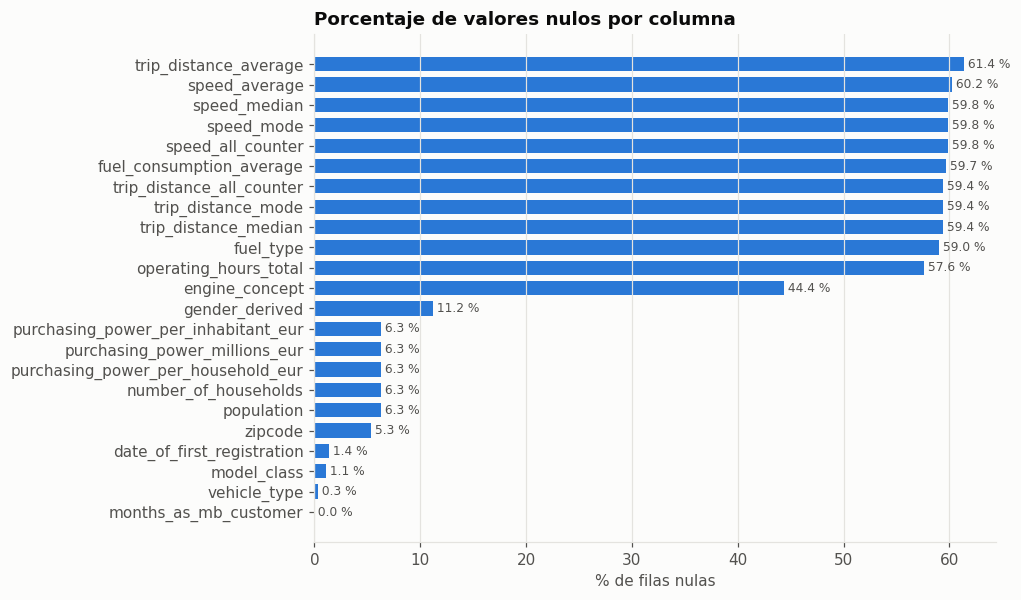

In [9]:
nulls = raw.isna().mean().mul(100).sort_values(ascending=True)
nulls = nulls[nulls > 0]
fig, ax = plt.subplots(figsize=(8, 6))
ps.bar(ax, nulls.index, nulls.values, fmt="{:.1f} %", horizontal=True)
ax.invert_yaxis()
ax.set_title("Porcentaje de valores nulos por columna")
ax.set_xlabel("% de filas nulas")
fig.savefig(FIG_DIR / "01_nulos.png"); plt.show()

Se distinguen **tres bloques de nulos** con causas distintas:

1. **Telemetría (~60 %)**: `trip_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average`. Faltan juntas → el vehículo no comparte datos de conducción (no conectado o sin consentimiento).
2. **Motorización (44-59 %)**: `engine_concept` y `fuel_type`. No depende de la antigüedad del coche (ver abajo) → es un hueco de catálogo, recuperable en parte desde `vehicle_type`.
3. **Zona geográfica (5-6 %)**: `zipcode` y las variables socioeconómicas, que faltan a la vez (CP no casado con la tabla sociodemográfica).

Y otros puntuales: `gender_derived` (11 %), `model_class` (1,1 %), `date_of_first_registration` (1,4 %), `months_as_mb_customer` (4 filas).

In [10]:
tele = ["trip_distance_average", "trip_distance_median", "operating_hours_total", "fuel_consumption_average", "speed_average"]
print("Correlación entre los indicadores de nulo de telemetría (faltan juntas):")
display(raw[tele].isna().astype(int).corr().round(2))
print("% sin telemetría según si el vehículo es actual:")
display(raw.groupby("is_current_vehicle").trip_distance_average.apply(lambda s: s.isna().mean()).mul(100).round(1))

Correlación entre los indicadores de nulo de telemetría (faltan juntas):


,trip_distance_average,trip_distance_median,operating_hours_total,fuel_consumption_average,speed_average
trip_distance_average,1.00,0.96,0.71,0.69,0.76
trip_distance_median,0.96,1.00,0.73,0.70,0.78
operating_hours_total,0.71,0.73,1.00,0.95,0.94
fuel_consumption_average,0.69,0.70,0.95,1.00,0.90
speed_average,0.76,0.78,0.94,0.90,1.00


% sin telemetría según si el vehículo es actual:


is_current_vehicle
False    74.3
True     52.6
Name: trip_distance_average, dtype: float64

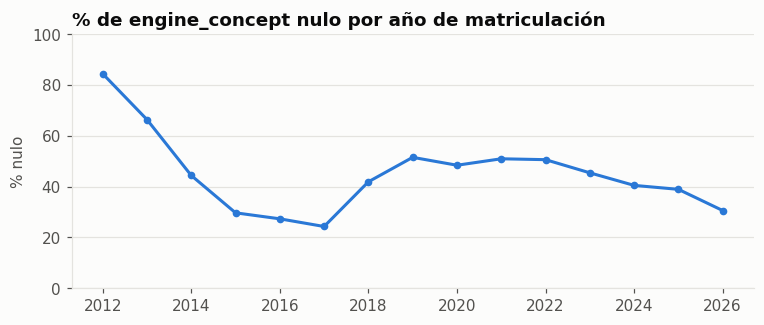

Modelos más frecuentes con engine_concept nulo:


vehicle_type
GLC 220 d 4MATIC    9688
C 220 d 4MATIC      6724
A 200               4059
C 200 4MATIC        3180
GLC 250 d 4MATIC    3010
GLC 300 4MATIC      2938
AMG A 35 4MATIC     2758
EQA 250             2433
EQA 350 4MATIC      2350
A 180 d             2313
Name: count, dtype: int64

In [11]:
reg_year = pd.to_datetime(raw.date_of_first_registration, errors="coerce").dt.year
miss_by_year = raw.engine_concept.isna().groupby(reg_year).mean().mul(100).loc[2012:]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(miss_by_year.index, miss_by_year.values, lw=2, marker="o", ms=4, color=ps.SERIES[0])
ax.set_ylim(0, 100); ax.set_title("% de engine_concept nulo por año de matriculación")
ax.set_ylabel("% nulo"); fig.savefig(FIG_DIR / "01_engine_null_year.png"); plt.show()
print("Modelos más frecuentes con engine_concept nulo:")
raw.loc[raw.engine_concept.isna(), "vehicle_type"].value_counts().head(10)

El nulo de motorización no está ligado a coches antiguos, y los modelos afectados (`EQA 250`, `A 250 e`, `GLC 300 de`…) permiten
**inferir la motorización desde el nombre comercial**: `EQ*` → eléctrico, sufijo `e`/`de` → híbrido enchufable, resto → combustión.

In [12]:
rows = mf.clean_rows(raw)
before = raw.engine_concept.isna().mean() * 100
after = rows.engine_concept_filled.isna().mean() * 100
print(f"engine_concept nulo: {before:.1f} % -> {after:.1f} % tras inferirlo desde vehicle_type")
# Validación de la regla sobre las filas donde engine_concept SÍ es conocido
known = raw.engine_concept.notna()
inferred = mf.infer_engine_concept(raw.vehicle_type[known], pd.Series(np.nan, index=raw.index[known]))
truth = raw.engine_concept[known].replace({"MILD_HYBRID": "COMBUSTION"})
print(f"Acierto de la regla en filas conocidas (MHEV≈combustión): {(inferred == truth).mean():.1%}")

engine_concept nulo: 44.4 % -> 0.3 % tras inferirlo desde vehicle_type


Acierto de la regla en filas conocidas (MHEV≈combustión): 94.5%


### Inconsistencias detectadas

In [13]:
checks = {}
checks["model_class nulo"] = raw.model_class.isna().sum()
checks["  → recuperable desde vehicle_type"] = (raw.model_class.isna() & rows.model_class.notna()).sum()
d = pd.to_datetime(raw.date_of_first_registration, errors="coerce")
checks["Matriculación anterior a 2000 (p. ej. 1987)"] = (d < "2000-01-01").sum()
checks["population == 0"] = (raw.population == 0).sum()
checks["  → de ellas con poder adquisitivo informado"] = ((raw.population == 0) & raw.purchasing_power_per_household_eur.notna()).sum()
checks["zipcode informado pero sin datos socioeconómicos"] = (raw.zipcode.notna() & raw.population.isna()).sum()
checks["months_as_mb_customer nulo"] = raw.months_as_mb_customer.isna().sum()
checks["months_as_mb_customer == 0"] = (raw.months_as_mb_customer == 0).sum()
checks["Clientes con role_type B2B y B2C a la vez"] = (raw.groupby("client_id").role_type.nunique() > 1).sum()
checks["speed_all_counter > p99.9 (outliers extremos)"] = (raw.speed_all_counter > raw.speed_all_counter.quantile(.999)).sum()
checks["fuel_type con varios valores ('DIESEL,ELECTRIC')"] = raw.fuel_type.str.contains(",", na=False).sum()
g = raw.groupby("client_id").agg(cur=("is_current_vehicle", "sum"), ccv=("currently_connected_vehicles", "first"))
checks["Clientes donde nº vehículos actuales != currently_connected_vehicles"] = (g.cur != g.ccv).sum()
pd.Series(checks, name="nº filas / clientes").to_frame()

,nº filas / clientes
model_class nulo,3369
→ recuperable desde vehicle_type,3368
Matriculación anterior a 2000 (p. ej. 1987),2
population == 0,73
→ de ellas con poder adquisitivo informado,0
zipcode informado pero sin datos socioeconómicos,2879
months_as_mb_customer nulo,4
months_as_mb_customer == 0,8634
Clientes con role_type B2B y B2C a la vez,545
speed_all_counter > p99.9 (outliers extremos),122


### Propuesta de tratamiento

| Problema | Tratamiento | Justificación |
|---|---|---|
| Granularidad cliente-vehículo | Agregar a 1 fila por cliente | Se segmentan clientes, no coches |
| `model_class` nulo (1,1 %) | Inferir desde el prefijo de `vehicle_type` (`GLC 400…` → GLC-Class) | Casi todos son modelos recientes reconocibles |
| `engine_concept` nulo (44 %) | Inferir desde `vehicle_type`; MHEV no detectable se agrupa con combustión | Recupera la info sin inventar una categoría de 44 % |
| `fuel_type` | No se usa; redundante con `engine_concept` y con valores compuestos | Evita duplicar señal |
| Matriculación < 2000 (2 filas de 1987) | Fijar a nulo e imputar con la mediana | Fecha implausible para un coche conectado |
| `population`/`households` = 0 (73 filas) | Fijar a nulo | Son zonas sin datos socioeconómicos (el poder adquisitivo también es nulo): el 0 es un falso valor |
| Socioeconómicas nulas (6 %) | Imputar con la **mediana** dentro del pipeline | Pocos nulos, distribución asimétrica |
| `gender_derived` nulo (11 %) | No se usa en el modelo; categoría `unknown` al perfilar | Es inferido, no declarado → riesgo de sesgo |
| Telemetría nula (60 %) | **Fuera del modelo**; solo para perfilar + flag `has_telemetry` | Imputar el 60 % crearía una masa artificial que K-Means convertiría en un cluster |
| `trip_distance_mode`, `speed_mode` | Descartar | Strings multivalor, redundantes |
| `speed_all_counter` outliers | Descartar (contador técnico) | No describe al cliente |
| `months_as_mb_customer` nulo (4 filas) | Imputar mediana | Irrelevante en volumen |
| Vehículos actuales vs `currently_connected_vehicles` | Coinciden (salvo 4 clientes) → se usa la columna oficial | Validación de consistencia |

## 5. Distribuciones de variables clave

Tabla de clientes: (173456, 36)


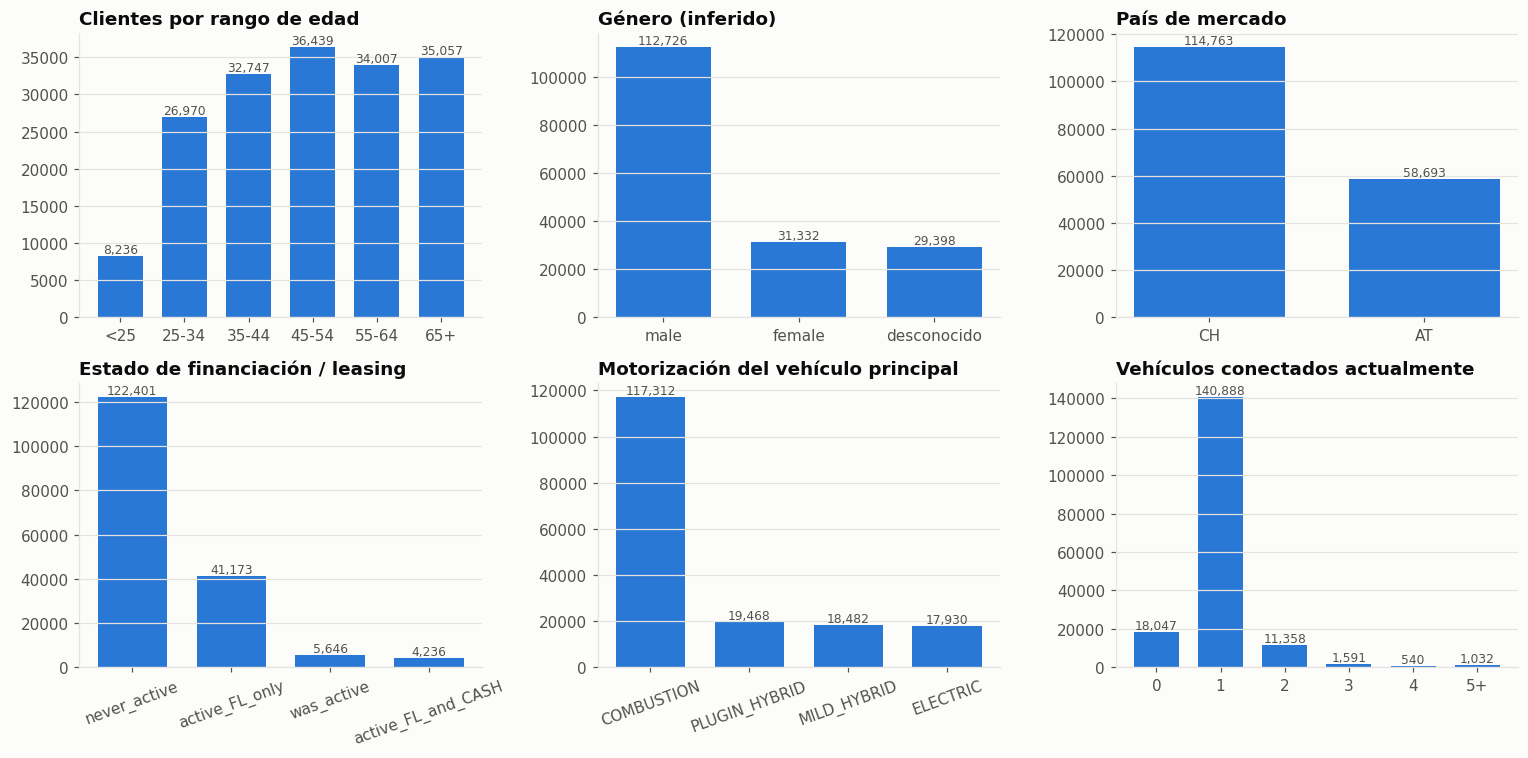

In [14]:
clients = mf.build_client_table(rows)
print(f"Tabla de clientes: {clients.shape}")
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
age = clients.age_range.value_counts().reindex(list(mf.AGE_ORDER))
ps.bar(axes[0, 0], age.index, age.values); axes[0, 0].set_title("Clientes por rango de edad")
gen = clients.gender_derived.fillna("desconocido").value_counts()
ps.bar(axes[0, 1], gen.index, gen.values); axes[0, 1].set_title("Género (inferido)")
cty = clients.country_code.value_counts()
ps.bar(axes[0, 2], cty.index, cty.values); axes[0, 2].set_title("País de mercado")
fin = clients.finance_leasing_status.value_counts()
ps.bar(axes[1, 0], fin.index, fin.values); axes[1, 0].set_title("Estado de financiación / leasing")
axes[1, 0].tick_params(axis="x", rotation=20)
eng = clients.main_engine_concept.value_counts()
ps.bar(axes[1, 1], eng.index, eng.values); axes[1, 1].set_title("Motorización del vehículo principal")
axes[1, 1].tick_params(axis="x", rotation=20)
ccv = clients.currently_connected_vehicles.clip(upper=5).value_counts().sort_index()
ps.bar(axes[1, 2], [str(int(i)) if i < 5 else "5+" for i in ccv.index], ccv.values)
axes[1, 2].set_title("Vehículos conectados actualmente")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_distribuciones_categoricas.png"); plt.show()

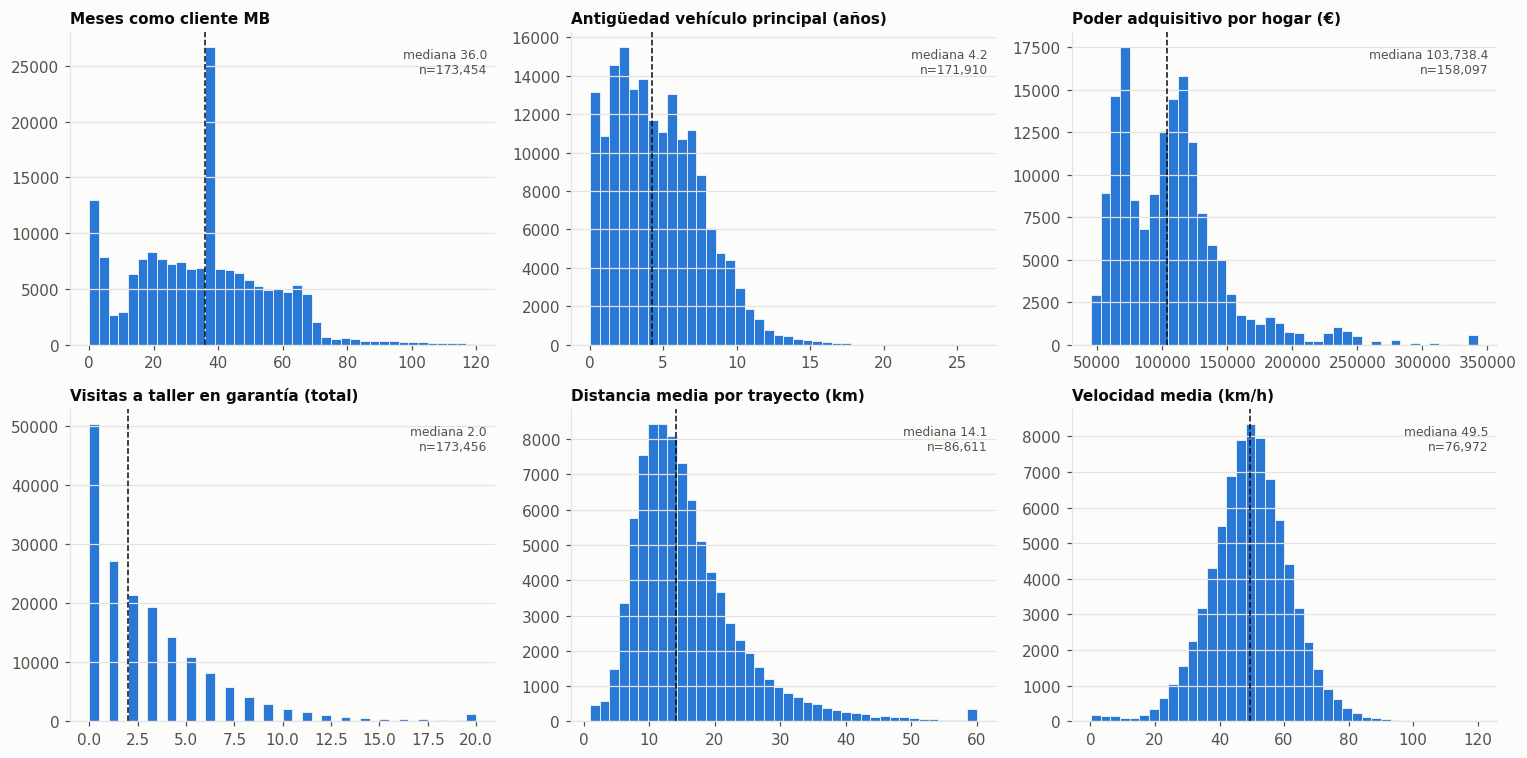

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
series = [("months_as_mb_customer", "Meses como cliente MB", None),
          ("main_vehicle_age_years", "Antigüedad vehículo principal (años)", None),
          ("purchasing_power_per_household_eur", "Poder adquisitivo por hogar (€)", None),
          ("workshop_visits_total", "Visitas a taller en garantía (total)", 20),
          ("trip_distance_average", "Distancia media por trayecto (km)", 60),
          ("speed_average", "Velocidad media (km/h)", 120)]
for ax, (c, title, cap) in zip(axes.ravel(), series):
    s = clients[c].dropna()
    if cap: s = s.clip(upper=cap)
    ax.hist(s, bins=40, color=ps.SERIES[0], edgecolor="#fcfcfb", linewidth=0.5)
    ax.axvline(s.median(), color=ps.INK, lw=1, ls="--")
    ax.set_title(title, fontsize=10)
    ax.text(0.98, 0.95, f"mediana {s.median():,.1f}\nn={len(s):,}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color=ps.INK_2)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_distribuciones_numericas.png"); plt.show()

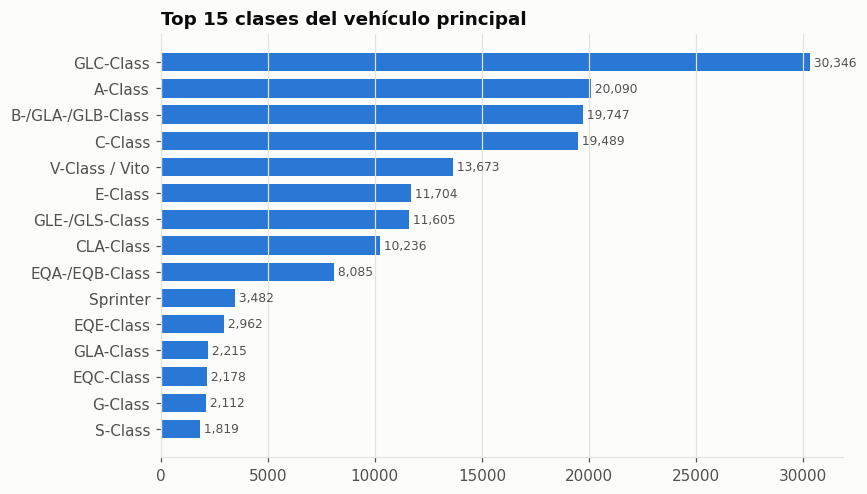

In [16]:
cls = clients.main_model_class.value_counts().head(15)
fig, ax = plt.subplots(figsize=(8, 5))
ps.bar(ax, cls.index, cls.values, horizontal=True)
ax.set_title("Top 15 clases del vehículo principal")
fig.savefig(FIG_DIR / "01_model_class.png"); plt.show()

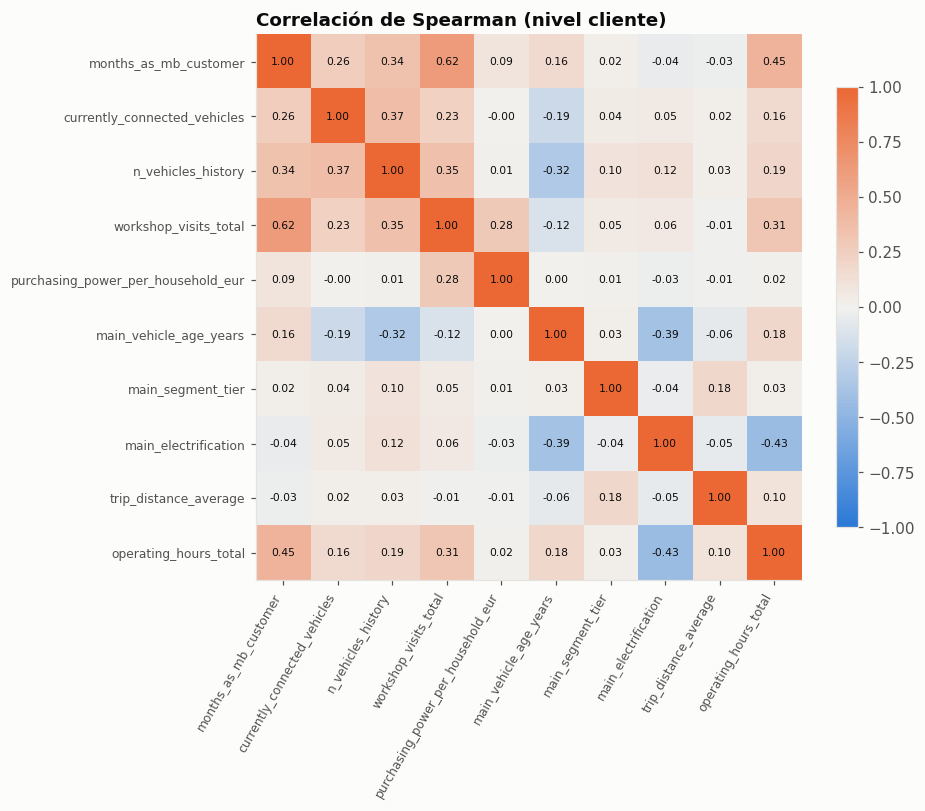

In [17]:
# Relaciones entre variables a nivel cliente
corr_cols = ["months_as_mb_customer", "currently_connected_vehicles", "n_vehicles_history", "workshop_visits_total",
             "purchasing_power_per_household_eur", "main_vehicle_age_years", "main_segment_tier", "main_electrification",
             "trip_distance_average", "operating_hours_total"]
c = clients[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap=ps.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(c)), c.columns, fontsize=8); ax.grid(False)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=ps.INK)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlación de Spearman (nivel cliente)")
fig.savefig(FIG_DIR / "01_correlaciones.png"); plt.show()

In [18]:
# Comparativa por país: ¿es el país una dimensión que domina?
clients.groupby("country_code")[["purchasing_power_per_household_eur", "months_as_mb_customer",
                                  "currently_connected_vehicles", "workshop_visits_total"]].median().round(1)

,purchasing_power_per_household_eur,months_as_mb_customer,currently_connected_vehicles,workshop_visits_total
country_code,,,,
AT,66938.2,30.5,1.0,1.0
CH,116082.4,36.0,1.0,3.0


## 6. Resumen de hallazgos y conclusiones

In [19]:
summary = {
    "Clientes": f"{len(clients):,}",
    "Relaciones cliente-vehículo": f"{len(raw):,}",
    "% Suiza / Austria": f"{(clients.country_code=='CH').mean():.0%} / {(clients.country_code=='AT').mean():.0%}",
    "% hombres / mujeres / desconocido (inferido)": " / ".join(f"{v:.0%}" for v in clients.gender_derived.fillna("na").value_counts(normalize=True)[["male","female","na"]]),
    "Edad más frecuente": clients.age_range.mode()[0],
    "% clientes 45+": f"{clients.age_range.isin(['45-54','55-64','65+']).mean():.0%}",
    "Mediana meses como cliente": f"{clients.months_as_mb_customer.median():.0f}",
    "% con 1 solo vehículo conectado": f"{(clients.currently_connected_vehicles==1).mean():.0%}",
    "% sin vehículo actual conectado": f"{(clients.currently_connected_vehicles==0).mean():.0%}",
    "% B2B": f"{clients.is_b2b.mean():.1%}",
    "% con financiación/leasing activo": f"{clients.finance_leasing_status.str.startswith('active').mean():.0%}",
    "% vehículo principal electrificado (PHEV/EV)": f"{(clients.main_electrification>=2).mean():.0%}",
    "% vehículo principal SUV": f"{clients.main_is_suv.mean():.0%}",
    "% con los 3 consentimientos": f"{(clients[['consent_phone_communication_channel','consent_epost_communication_channel','consent_post_communication_channel']].all(axis=1)).mean():.0%}",
    "% con telemetría": f"{clients.has_telemetry.mean():.0%}",
}
pd.Series(summary, name="valor").to_frame()

,valor
Clientes,"173,456"
Relaciones cliente-vehículo,"302,850"
% Suiza / Austria,66% / 34%
% hombres / mujeres / desconocido (inferido),65% / 18% / 17%
Edad más frecuente,45-54
% clientes 45+,61%
Mediana meses como cliente,36
% con 1 solo vehículo conectado,81%
% sin vehículo actual conectado,10%
% B2B,0.6%


### ¿Cuáles son las principales características de los clientes?

- **Mercado alpino y maduro**: ~66 % de los clientes son de **Suiza** y ~34 % de **Austria**, con un poder adquisitivo por hogar muy alto (mediana ≈ 100 k€, y claramente superior en Suiza).
- **Perfil de edad media-alta**: el 61 % tiene 45 años o más y los menores de 25 son marginales (<5 %). Según el género inferido, ~78 % de los clientes con género conocido son hombres (17 % sin dato).
- **Relación reciente pero estable**: mediana de ~3 años como cliente conectado (máx. 10). El 81 % tiene **un único vehículo** conectado; ~10 % no tiene ningún vehículo activo (posible fuga) y una minoría multi-vehículo / flota concentra muchos coches. Solo el 0,6 % es B2B.
- **Producto**: dominan SUV y gamas compacta-media (**GLC, Clase C, Clase A, GLA/GLB**). Furgonetas (V-Class/Vito, Sprinter) son un nicho relevante. La electrificación (PHEV + EV) ya alcanza a ~1 de cada 5 vehículos principales (22 %).
- **Financiación**: ~29 % ha usado alguna vez leasing/financiación de Mercedes (26 % con contrato activo); el resto compra al contado o fuera de la marca.
- **Comunicación**: la gran mayoría acepta email (98 %), teléfono (86 %) y correo postal (85 %); el 81 % acepta los tres → los canales no discriminan mucho entre clientes.
- **Conectividad**: solo la mitad de los clientes tiene algún vehículo con telemetría de conducción.

### ¿Qué problemas de calidad hemos encontrado y cómo los hemos resuelto?

1. **Granularidad mixta** (cliente-vehículo) → agregación a cliente con "vehículo principal" + agregados de historial.
2. **Bloque de telemetría con 60 % de nulos** → excluido del clustering, usado solo para perfilar.
3. **Motorización nula al 44 %** → inferida desde el nombre comercial (≈95 % de acierto validado sobre los datos conocidos).
4. **`model_class` nulo** (1,1 %) → inferido desde `vehicle_type` (3.368 de 3.369 filas recuperadas).
5. **Fechas implausibles** (1987) y **población = 0** (zonas sin datos) → a nulo e imputación por mediana.
6. **Columnas sin valor analítico** (índice, IDs, CP, modas multivalor, contadores técnicos) → excluidas.
7. **Variables sensibles inferidas** (`gender_derived`) → fuera del modelo para no segmentar por un atributo no declarado.